In [144]:
import matplotlib.pyplot as plt
import networkx as nx
import h5py
import numpy as np
import pandas as pd
import re
import os
import sys

import mouse1d_analysis as m1da

sys.path.append("/../../HALnalysis")
import analysis_package as mla

from mouse1d_analysis import Burst

import regex as re

In [145]:
#Get bursts from raw data
homedir=os.path.expanduser("~")

#filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/7-9 mouse_1d_test/7/well4/"
#filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/2h_7-12/M07484/240712/4/well4/"
#filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/DIV13/M07475/240716/0/well1/"
#filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/DIV13_no_media_change/M07472/240716/1/well0/"
#filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/DIV15_mouse1d/M07475/240718/3/well1/"
filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/mouse1d_direction_test/M07472/240719/8/well4/"

#filename = "DIV15_mouse1d_well_1"
#filename = "DIV13_no_media_change_well_0"
filename = "mouse1d_direction_test_well_4"
filetag = ".raw.h5"
datapath = homedir + "/Documents/HAL/data/wes_analysis/"
well_no = 4
recording_no = 0

In [146]:
events = mla.load_events(filepath + filename + filetag, well_no)
display(events)

,frameno,eventtype,eventid,eventmessage,frameno_adjusted,time,eventmessage_decoded
0,112045402,1,1,"b'{""before_training"":""1""}\n'",50054,5.0054,"{""before_training"":""1""}\n"
1,112045452,1,7,"b'{""map"":""1000"",""moveto"":""3"",""object"":""0""}\n'",50104,5.0104,"{""map"":""1000"",""moveto"":""3"",""object"":""0""}\n"
2,112168456,1,6,"b'{""map"":""1000"",""moveto"":""2"",""object"":""0""}\n'",173108,17.3108,"{""map"":""1000"",""moveto"":""2"",""object"":""0""}\n"
3,112516574,1,5,"b'{""map"":""1000"",""moveto"":""1"",""object"":""0""}\n'",521226,52.1226,"{""map"":""1000"",""moveto"":""1"",""object"":""0""}\n"
4,112801997,1,4,"b'{""map"":""1000"",""moveto"":""0"",""object"":""1""}\n'",806649,80.6649,"{""map"":""1000"",""moveto"":""0"",""object"":""1""}\n"
...,...,...,...,...,...,...,...
991,118029233,1,124,"b'{""amp_mV"":""40.0"",""dac"":""1"",""num_trains"":""1"",...",6033885,603.3885,"{""amp_mV"":""40.0"",""dac"":""1"",""num_trains"":""1"",""p..."
992,118039760,1,123,"b'{""amp_mV"":""40.0"",""dac"":""0"",""end_stimulation""...",6044412,604.4412,"{""amp_mV"":""40.0"",""dac"":""0"",""end_stimulation"":""..."
993,118039761,1,127,"b'{""end_stimulation"":""loc2_distance""}\n'",6044413,604.4413,"{""end_stimulation"":""loc2_distance""}\n"
994,118039810,1,126,"b'{""start_stimulation"":""loc2_distance""}\n'",6044462,604.4462,"{""start_stimulation"":""loc2_distance""}\n"


In [147]:
pre_train_movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])
train_movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])
movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])
full_movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])


current_pos = -1
world = None

for i in events.index:
    
    message = events.loc[i, "eventmessage_decoded"]
    if "moveto" in message:
        numbers = [int(num) for num in re.findall(r'\d+', message)]
        if not world:
            world = list(str(numbers[0]))
        new_pos = numbers[1]
        
        if new_pos != current_pos:
            movement_df.loc[len(movement_df), :] = [events.loc[i, "frameno_adjusted"], events.loc[i, "time"], new_pos]
            full_movement_df.loc[len(full_movement_df), :] = [events.loc[i, "frameno_adjusted"], events.loc[i, "time"], new_pos]
            current_pos = new_pos
    elif message == "{\"training\":\"1\"}\n":
        train_time = events.loc[i, "time"]
        print("switch to train at time " + str(train_time))
        pre_train_movement_df = movement_df
        movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])


train_movement_df = movement_df
full_movement_df



switch to train at time 305.0176


,frameno,time,position
0,50104,5.0104,3
1,173108,17.3108,2
2,521226,52.1226,1
3,806649,80.6649,0
4,1078790,107.879,3
5,1099692,109.9692,0
6,1291031,129.1031,3
7,1685012,168.5012,2
8,2165803,216.5803,3
9,2433916,243.3916,2


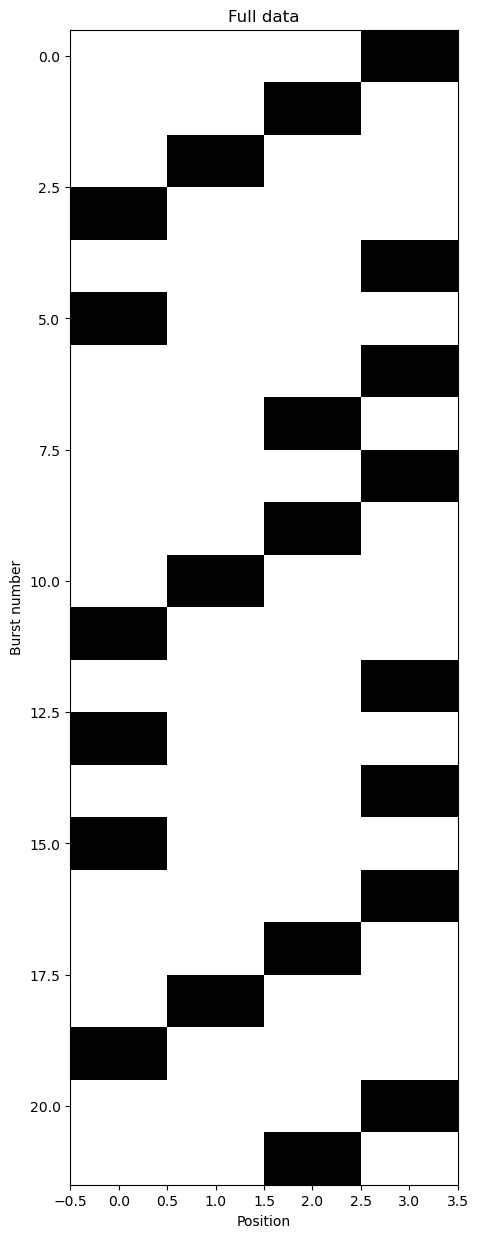

In [148]:
xtplot = np.zeros((len(full_movement_df), 1 + max(full_movement_df["position"])))
for i in full_movement_df.index:
    xtplot[i, full_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 15))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("Full data")
plt.ylabel("Burst number")
plt.xlabel("Position")
plt.show()
#plt.close()

xtplot = np.zeros((len(pre_train_movement_df), 1 + max(pre_train_movement_df["position"])))
for i in pre_train_movement_df.index:
    xtplot[i, pre_train_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 10))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("No stim")
plt.ylabel("Burst number")
plt.xlabel("Position")
#plt.show()
plt.close()


xtplot = np.zeros((len(train_movement_df), 1 + max(train_movement_df["position"])))
for i in train_movement_df.index:
    xtplot[i, train_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 10))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("Stim")
plt.ylabel("Burst number")
plt.xlabel("Position")
#plt.show()
plt.close()


In [149]:

midway = (min(train_movement_df["frameno"]) + max(train_movement_df["frameno"]))/2

first_half_train_movement_df = train_movement_df.loc[train_movement_df["frameno"] < midway, :].reset_index()
second_half_train_movement_df = train_movement_df.loc[train_movement_df["frameno"] > midway, :].reset_index()

midway = (min(pre_train_movement_df["frameno"]) + max(pre_train_movement_df["frameno"]))/2

first_half_pre_train_movement_df = pre_train_movement_df.loc[pre_train_movement_df["frameno"] < midway, :].reset_index()
second_half_pre_train_movement_df = pre_train_movement_df.loc[pre_train_movement_df["frameno"] > midway, :].reset_index()

In [150]:
train_transition_df = m1da.build_transition_df(train_movement_df, world)
pre_train_transition_df = m1da.build_transition_df(pre_train_movement_df, world)
first_half_train_transition_df = m1da.build_transition_df(first_half_train_movement_df, world)
second_half_train_transition_df = m1da.build_transition_df(second_half_train_movement_df, world)

first_half_pre_train_transition_df = m1da.build_transition_df(first_half_pre_train_movement_df, world)
second_half_pre_train_transition_df = m1da.build_transition_df(second_half_pre_train_movement_df, world)

train_transition_df

,leftward,rightward,total,proportion left,object
0,4.0,0.0,4.0,1.0,1
1,1.0,0.0,1.0,1.0,0
2,1.0,0.0,1.0,1.0,0
3,2.0,2.0,4.0,0.5,0


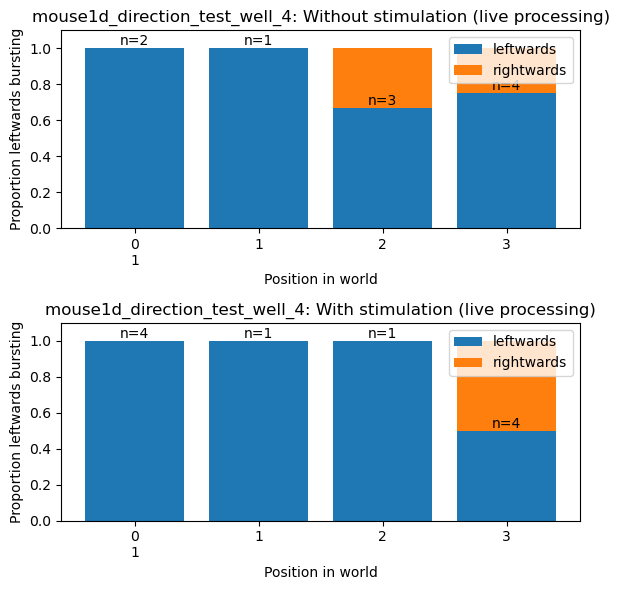

In [151]:
plt.figure(figsize = (6, 6))
ax = plt.subplot(212)
plt.title(filename + ": With stimulation (live processing)")
m1da.make_probability_bars(train_transition_df, world)

ax = plt.subplot(211)
plt.title(filename + ": Without stimulation (live processing)")
m1da.make_probability_bars(pre_train_transition_df, world)

plt.tight_layout()

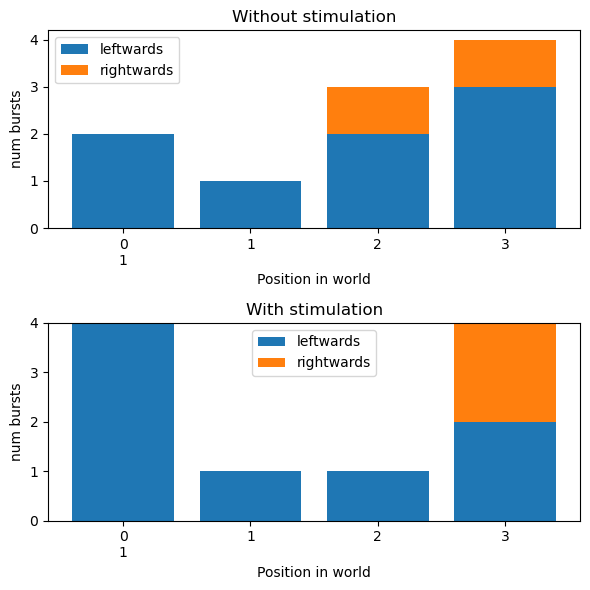

In [152]:
plt.figure(figsize = (6, 6))
ax = plt.subplot(212)
plt.title("With stimulation")
m1da.make_count_bars(train_transition_df, world)

ax = plt.subplot(211)
plt.title("Without stimulation")
m1da.make_count_bars(pre_train_transition_df, world)

plt.tight_layout()
plt.show()

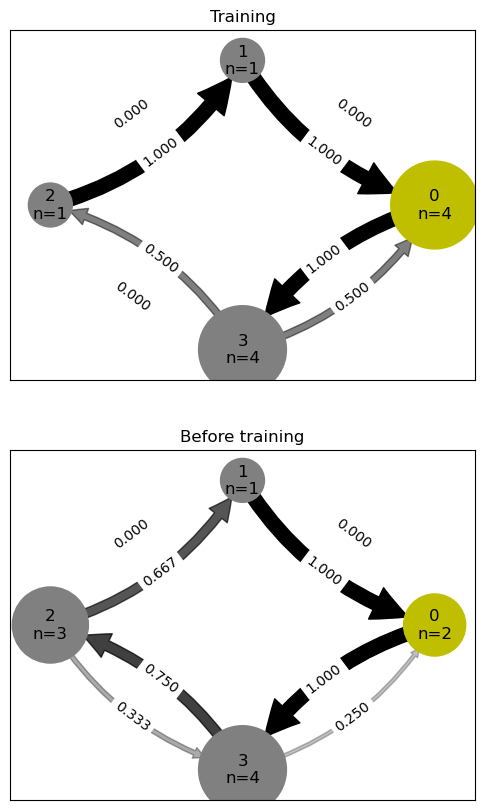

In [153]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("Training")
m1da.make_network_graph(train_transition_df, world)
plt.subplot(212)
plt.title("Before training")
m1da.make_network_graph(pre_train_transition_df, world)

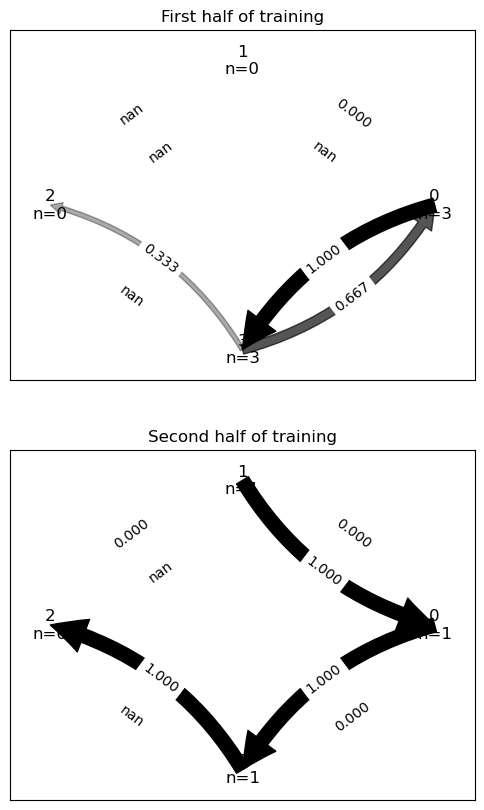

In [154]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("First half of training")
m1da.make_network_graph(first_half_train_transition_df, world)
plt.subplot(212)
plt.title("Second half of training")
m1da.make_network_graph(second_half_train_transition_df, world)

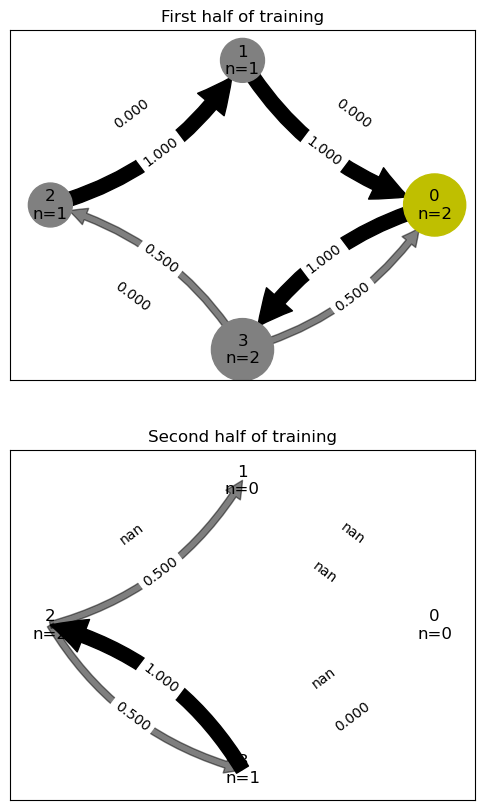

In [155]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("First half of training")
m1da.make_network_graph(first_half_pre_train_transition_df, world)
plt.subplot(212)
plt.title("Second half of training")
m1da.make_network_graph(second_half_pre_train_transition_df, world)

# Process the real data and get burst direction probabilities

In [156]:
display( train_movement_df)
display(pre_train_movement_df)
display(full_movement_df)

,frameno,time,position
0,3082107,308.2107,0
1,3265144,326.5144,3
2,3466888,346.6888,0
3,3766679,376.6679,3
4,4053426,405.3426,0
5,4289651,428.9651,3
6,4395760,439.576,2
7,4703802,470.3802,1
8,5075519,507.5519,0
9,5449647,544.9647,3


,frameno,time,position
0,50104,5.0104,3
1,173108,17.3108,2
2,521226,52.1226,1
3,806649,80.6649,0
4,1078790,107.879,3
5,1099692,109.9692,0
6,1291031,129.1031,3
7,1685012,168.5012,2
8,2165803,216.5803,3
9,2433916,243.3916,2


,frameno,time,position
0,50104,5.0104,3
1,173108,17.3108,2
2,521226,52.1226,1
3,806649,80.6649,0
4,1078790,107.879,3
5,1099692,109.9692,0
6,1291031,129.1031,3
7,1685012,168.5012,2
8,2165803,216.5803,3
9,2433916,243.3916,2


['events', 'groups', 'recording_id', 'settings', 'spikes', 'start_time', 'stop_time', 'well_id']
files not found
Binning data...
            time  channel  amplitude
0        -0.0325      662 -10.316845
1        -0.0325      695  -4.410600
2        -0.0325      694   6.673315
3        -0.0325      690 -17.103180
4        -0.0325      687  10.970589
...          ...      ...        ...
978592  604.8513      473   4.627560
978593  604.9116      347   6.688828
978594  604.9201      317  -4.090529
978595  604.9661      347   6.686607
978596  604.9710      698   5.168947

[978597 rows x 3 columns]


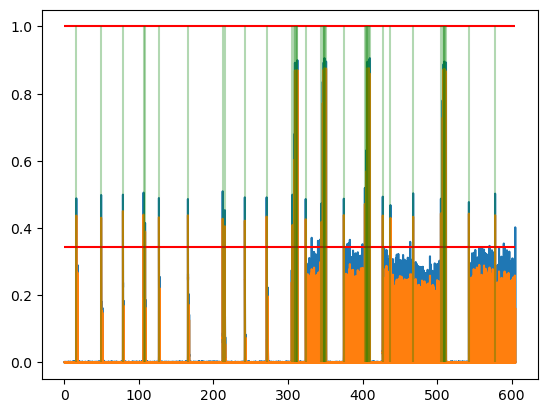

burst found in bin 1603 (time 15.99 s)
burst found in bin 4932 (time 49.28 s)
burst found in bin 7854 (time 78.50 s)
burst found in bin 10623 (time 106.19 s)
burst found in bin 10827 (time 108.23 s)
burst found in bin 12683 (time 126.79 s)
burst found in bin 16574 (time 165.70 s)
burst found in bin 21236 (time 212.32 s)
burst found in bin 21526 (time 215.22 s)
burst found in bin 24207 (time 242.03 s)
burst found in bin 27134 (time 271.30 s)
burst found in bin 30598 (time 305.94 s)
burst found in bin 30824 (time 308.20 s)
burst found in bin 30934 (time 309.30 s)
burst found in bin 31046 (time 310.42 s)
burst found in bin 31155 (time 311.51 s)
burst found in bin 31265 (time 312.61 s)
burst found in bin 32374 (time 323.70 s)
burst found in bin 34487 (time 344.83 s)
burst found in bin 34673 (time 346.69 s)
burst found in bin 34783 (time 347.79 s)
burst found in bin 34893 (time 348.89 s)
burst found in bin 35002 (time 349.98 s)
burst found in bin 35113 (time 351.09 s)
burst found in bin 374

In [157]:
burst_list = m1da.find_bursts(filepath, filename, well_no, recording_no, burst_thresh = 6, datapath = datapath, stim_thresh = 0.6) # don't filter out stimulations by burst size - do it with events.
print(len(burst_list))

In [158]:
p = re.compile(r"stimulation\":\"\L<world_locs>\"", world_locs=set(world))

#this intermediate step isn't actually necessary
stimulation_events = events.loc[["stimulation" in i for i in events["eventmessage_decoded"]], :]
# for i in stimulation_events["eventmessage_decoded"]:
#     print(i)


big_stimulation_events = stimulation_events.loc[[not (p.search(i) is None) for i in stimulation_events["eventmessage_decoded"]], :]
big_stimulation_events.head()

,frameno,eventtype,eventid,eventmessage,frameno_adjusted,time,eventmessage_decoded
26,115077505,1,138,"b'{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""...",3082157,308.2157,"{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""ph..."
27,115133083,1,139,"b'{""amp_mV"":""200"",""dac"":""2"",""end_stimulation"":...",3137735,313.7735,"{""amp_mV"":""200"",""dac"":""2"",""end_stimulation"":""1..."
142,115462286,1,138,"b'{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""...",3466938,346.6938,"{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""ph..."
143,115517864,1,139,"b'{""amp_mV"":""200"",""dac"":""2"",""end_stimulation"":...",3522516,352.2516,"{""amp_mV"":""200"",""dac"":""2"",""end_stimulation"":""1..."
323,116048825,1,138,"b'{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""...",4053477,405.3477,"{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""ph..."


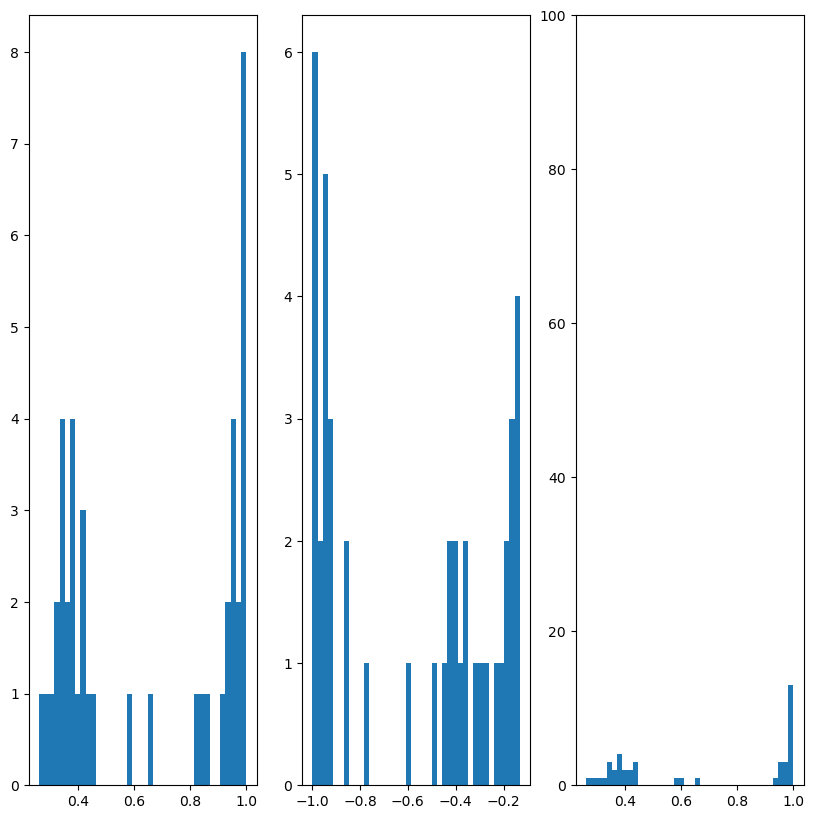

(-1.0, 0.0)

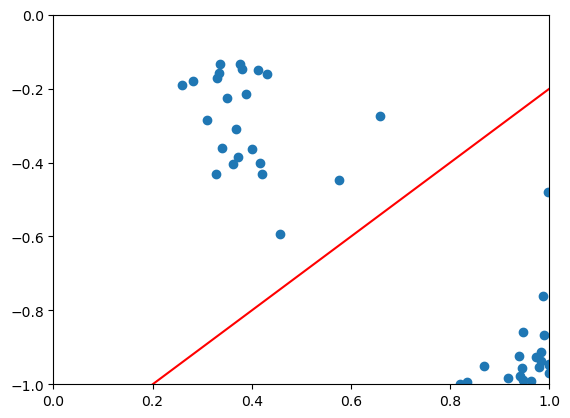

In [159]:
onset_list = list()
offset_list = list()
maxes = list()

const = -0.2

for i in burst_list:
    onset_frac = i.calculate_onset_offset(1)[1]/i.max_height()
    offset_frac = i.calculate_onset_offset(1)[0]/i.max_height()
    max_val = max(onset_frac, -offset_frac)
    #if 0.61 > max_val > 0.5:
    #   i.plot()
    #   print(i.calculate_onset_offset())
    #   print(onset_frac)
    #   print(offset_frac)
    onset_list.append(onset_frac)
    offset_list.append(offset_frac)
    maxes.append(max(onset_frac, -offset_frac))

plt.figure(figsize = (10, 10))
plt.subplot(131)
plt.hist(onset_list, 40)
plt.subplot(132)
plt.hist(offset_list, 40)
plt.subplot(133)
plt.hist(maxes, 40)
plt.ylim(0, 100)
plt.show()
#plt.plot(offset_list)
#plt.plot()
plt.figure()
plt.scatter(onset_list, offset_list)
x = np.arange(-1, 2, 0.1)
y = x - 1 + const
plt.plot(x, y, "r")
plt.xlim(0, 1)
plt.ylim(-1, 0)

In [160]:
trimmed_burst_list = list()
thresh = 0.75

#First remove the stims that we know we don't care about.
for i, burst in enumerate(burst_list):
    time = burst.time
    sub_big_stimulation_events = big_stimulation_events.loc[big_stimulation_events["time"] < time + 0.5].reset_index(drop = True)
    if len(sub_big_stimulation_events) > 0 and "start_stimulation" in sub_big_stimulation_events.loc[len(sub_big_stimulation_events) - 1, "eventmessage_decoded"]:
        #print(sub_big_stimulation_events.loc[len(sub_big_stimulation_events) - 1, :])
        print("removing burst at time " + str(time))
    else:
        trimmed_burst_list.append(burst)

print("Secondary burst removal:")
second_trimmed_burst_list= list()
for i, burst in enumerate(trimmed_burst_list):
    onset_frac = burst.calculate_onset_offset()[1]/burst.max_height()
    offset_frac = burst.calculate_onset_offset()[0]/burst.max_height()
    max_val = max(onset_frac, -offset_frac)
    time = burst.time
    #if max_val > thresh:
    #    print("removing burst at time " + str(time))
    
    if onset_frac - offset_frac > (1 - const):
        print("removing burst at time " + str(time))
    else:
        second_trimmed_burst_list.append(burst)

print(len(second_trimmed_burst_list))

print("Tertiary burst removal:")
for i in range(len(second_trimmed_burst_list) - 1, 1, -1):
    if second_trimmed_burst_list[i].time - 1.5 < second_trimmed_burst_list[i-1].time:
        second_trimmed_burst_list.pop(i)

print(len(second_trimmed_burst_list))

removing burst at time 308.20000000000005
removing burst at time 309.3
removing burst at time 310.42
removing burst at time 311.51000000000005
removing burst at time 312.61
removing burst at time 346.69000000000005
removing burst at time 347.79
removing burst at time 348.89000000000004
removing burst at time 349.9800000000001
removing burst at time 351.09000000000003
removing burst at time 404.99000000000007
removing burst at time 405.32000000000005
removing burst at time 406.43000000000006
removing burst at time 407.5300000000001
removing burst at time 408.62000000000006
removing burst at time 409.7300000000001
removing burst at time 507.5200000000001
removing burst at time 508.63000000000005
removing burst at time 509.74000000000007
removing burst at time 510.8400000000001
removing burst at time 511.9500000000001
Secondary burst removal:
22
Tertiary burst removal:
22


In [161]:
print([i.time for i in second_trimmed_burst_list])
for i in list(second_trimmed_burst_list)[-20:0]:
    i.plot()
    print(i.burst_direction(0.1))

[15.990000000000006, 49.28000000000001, 78.50000000000001, 106.19000000000001, 108.23000000000002, 126.79000000000002, 165.70000000000005, 212.32000000000005, 215.22000000000006, 242.03000000000006, 271.3, 305.94000000000005, 323.70000000000005, 344.83000000000004, 374.87000000000006, 403.15000000000003, 427.13000000000005, 437.46000000000004, 467.95000000000005, 505.1700000000001, 542.7100000000002, 577.9100000000002]


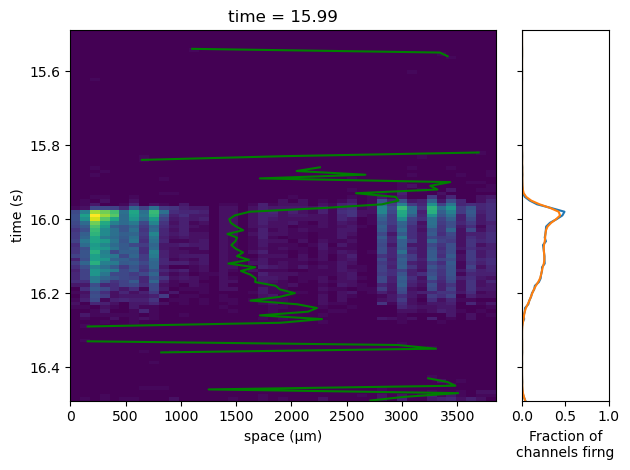

-1480.4362122940279


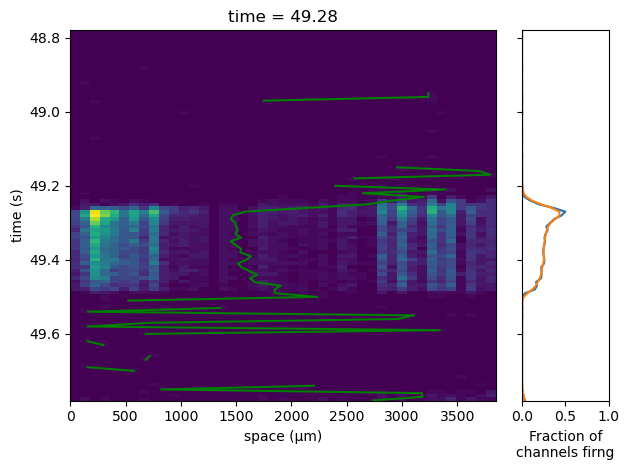

-1436.3874753107934


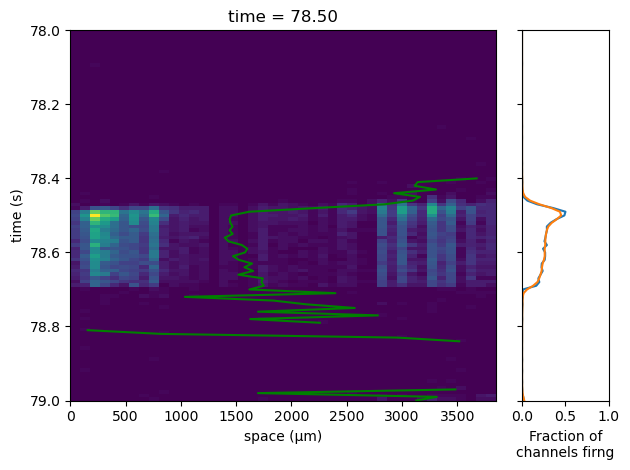

-1384.0410690073504


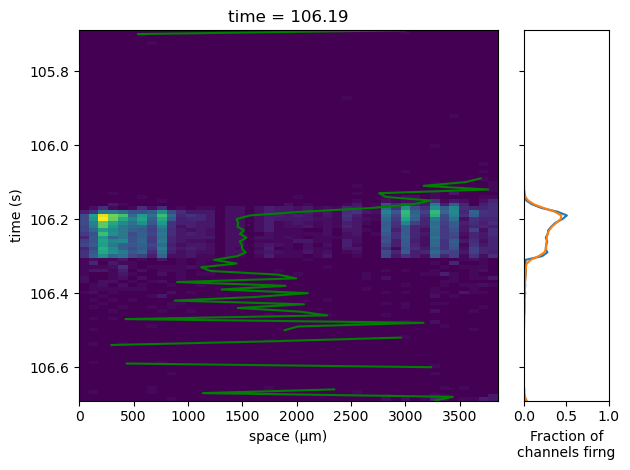

-1486.875


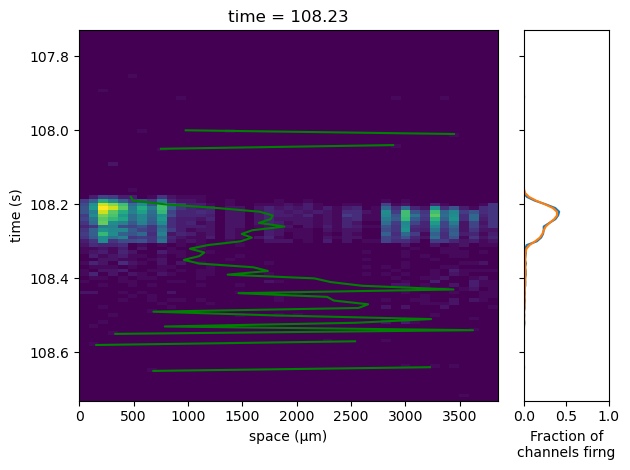

1281.6967894900497


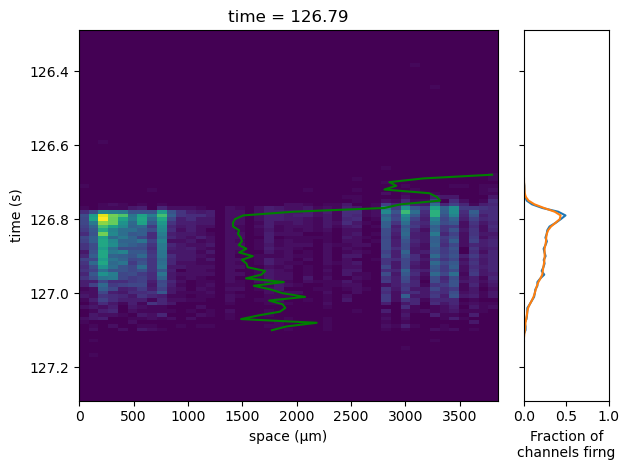

-1447.9755806010928


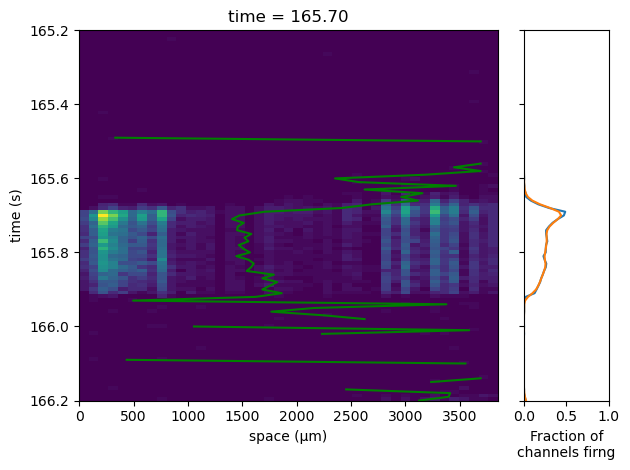

-1639.9235748966014


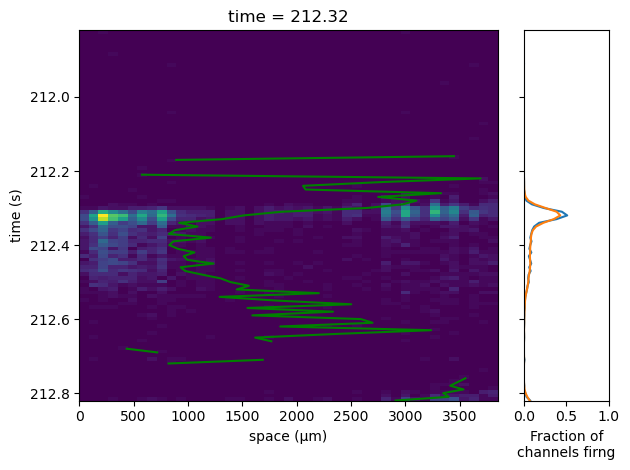

-1465.0226895980109


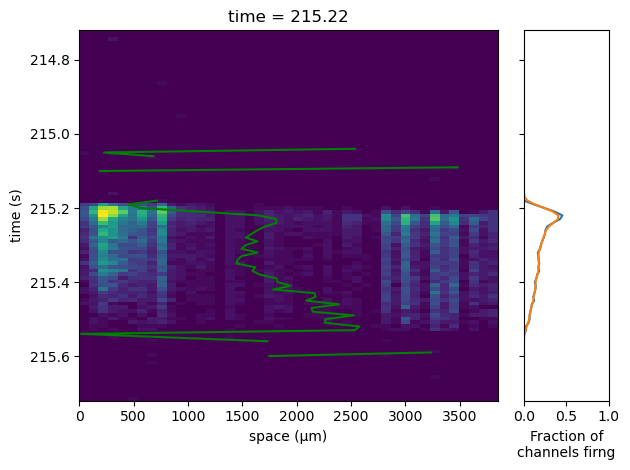

1199.991631396691


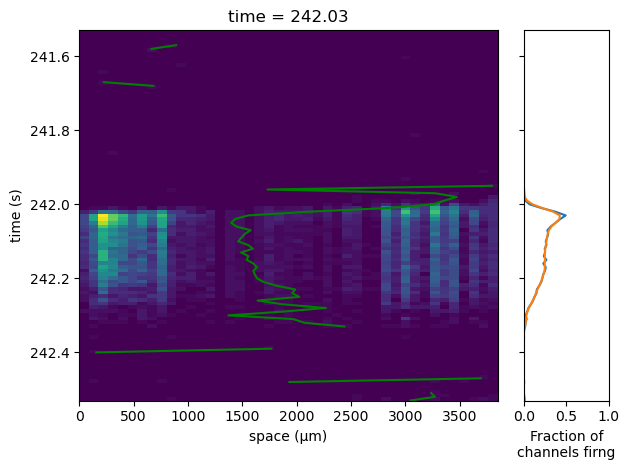

-1702.128151260504


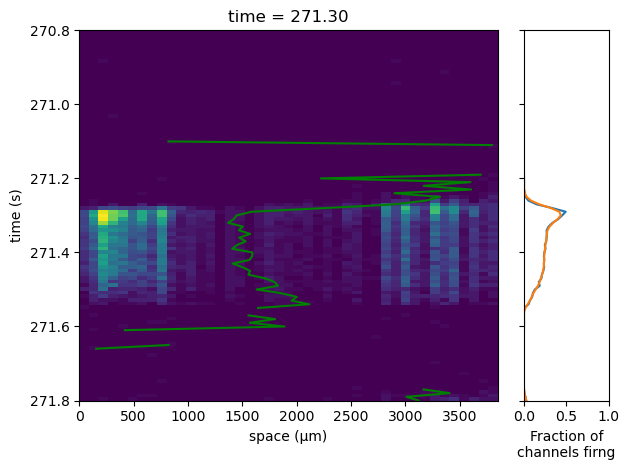

-1458.0397881177391


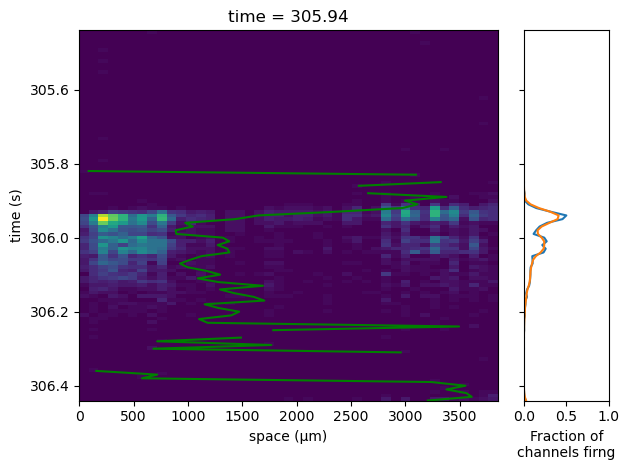

-1324.6174352582748


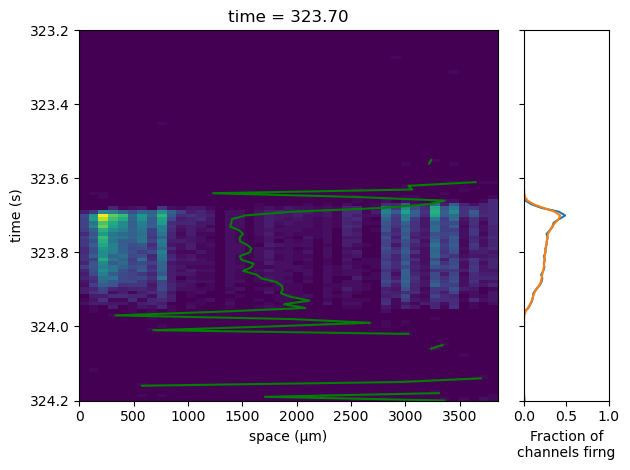

-1689.2679254025254


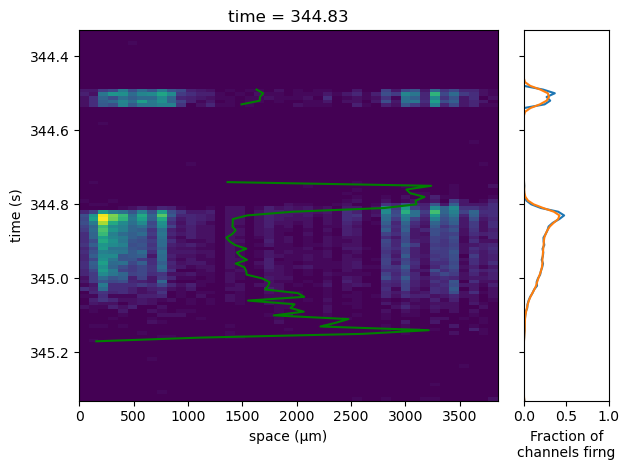

-1556.6604568478472


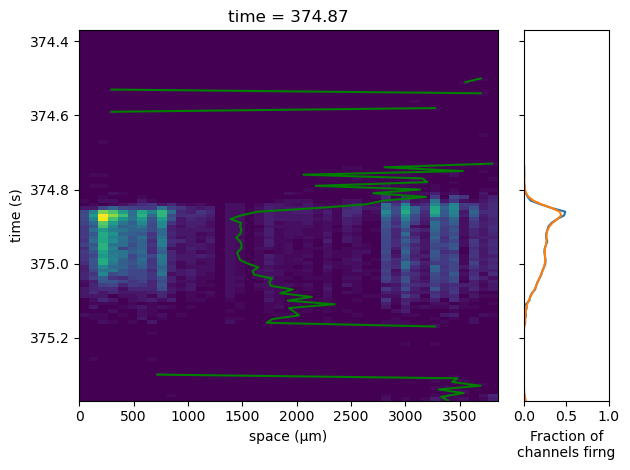

-1309.9936440677966


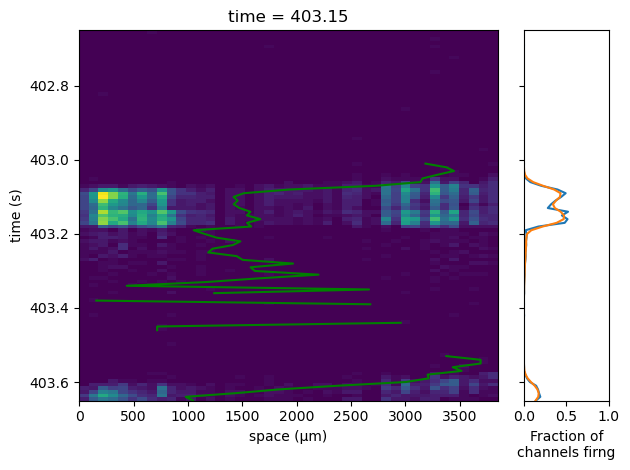

-1595.1916021198533


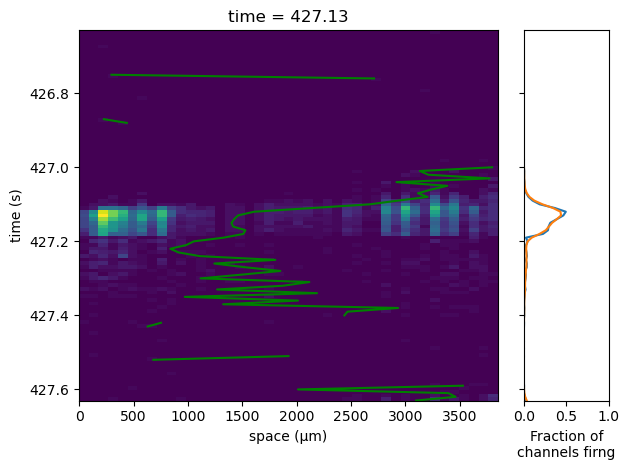

-1469.6880832057707


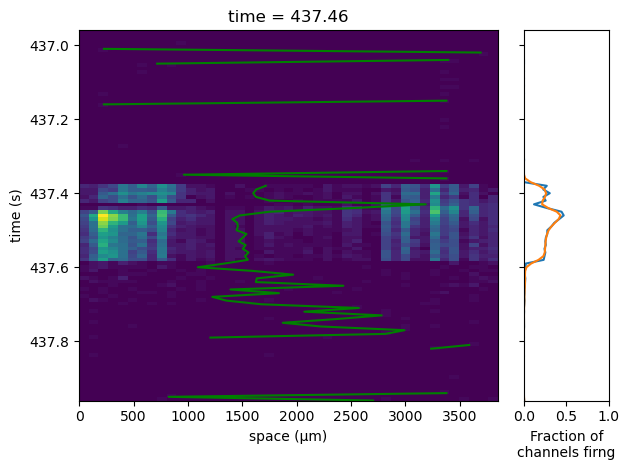

-237.4694124483574


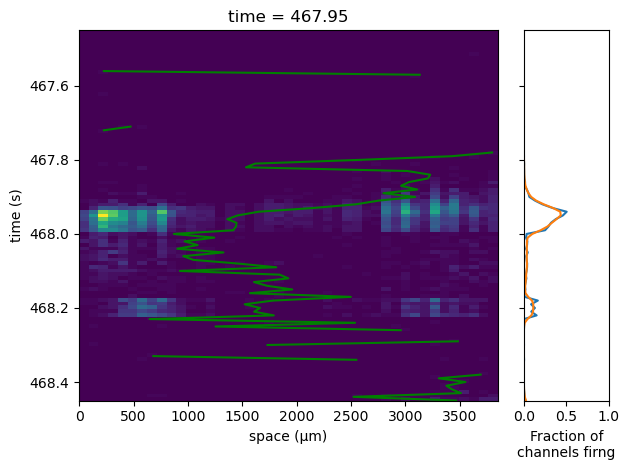

-1296.3679622654088


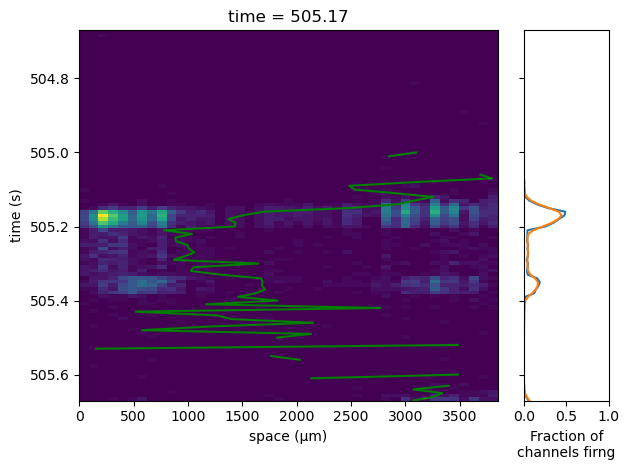

-1420.3141711229946


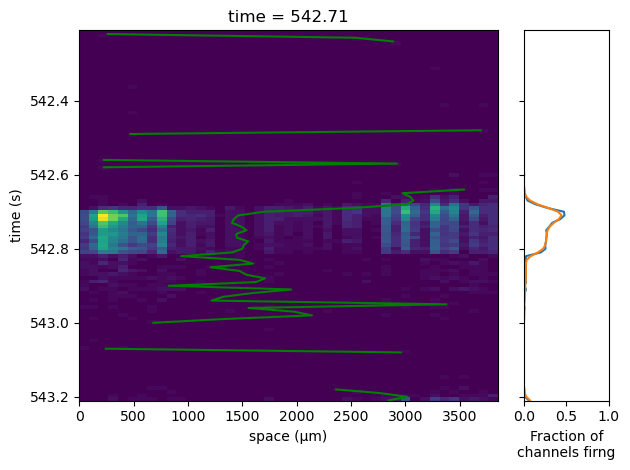

-1548.356777493606


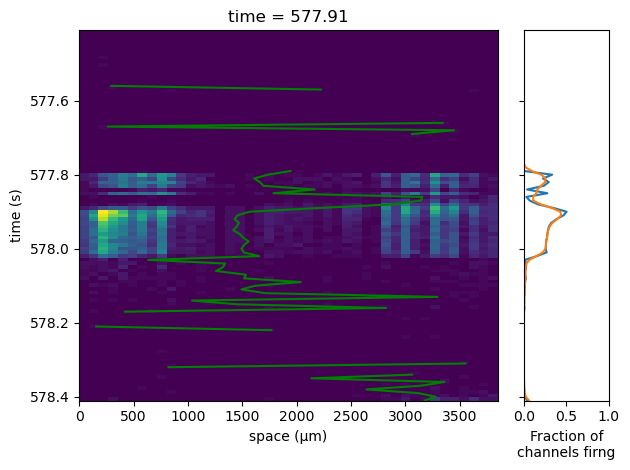

-281.85751645892424


In [168]:
for i in second_trimmed_burst_list:
    i.plot()
    print(i.direction())

In [163]:
def get_position_when_burst(burst: Burst, movement_df: pd.DataFrame)-> int:
    time = burst.time

    position = 0
    

    for i in movement_df.index:
        previous_position = position

        transition_time = movement_df.loc[i, "time"]
        position = movement_df.loc[i, "position"]

        if time < transition_time:
            return previous_position
    

    return position
    

3
2
1
0
3
0
3
2
2
3
2
1
0
3
0
3
0
3
2
1
0
3


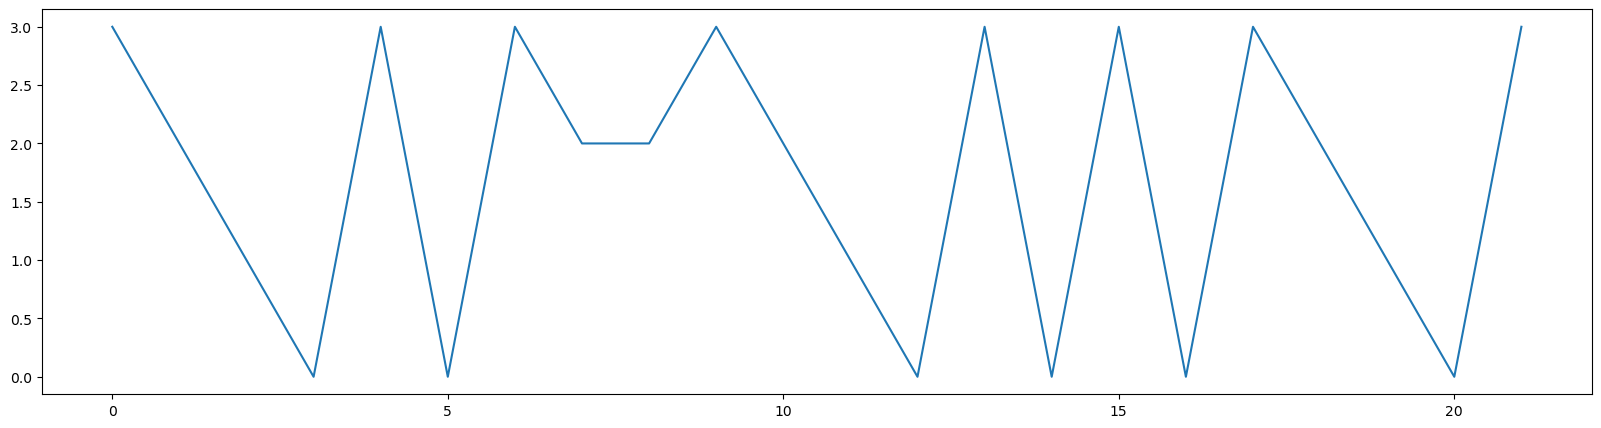

In [164]:
for burst in second_trimmed_burst_list:
    print(get_position_when_burst(burst, full_movement_df))

plt.figure(figsize = (20, 5))
plt.plot([get_position_when_burst(i, full_movement_df) for i in second_trimmed_burst_list])

In [165]:
raw_data_transition_df = pd.DataFrame(columns = ["leftward", "rightward", "total", "proportion left", "object"], index = range(0, len(world)))
pre_train_raw_data_transition_df = pd.DataFrame(columns = ["leftward", "rightward", "total", "proportion left", "object"], index = range(0, len(world)))
train_raw_data_transition_df = pd.DataFrame(columns = ["leftward", "rightward", "total", "proportion left", "object"], index = range(0, len(world)))
raw_data_transition_df["leftward"] = 0
raw_data_transition_df["rightward"] = 0
train_raw_data_transition_df["leftward"] = 0
train_raw_data_transition_df["rightward"] = 0
pre_train_raw_data_transition_df["leftward"] = 0
pre_train_raw_data_transition_df["rightward"] = 0


raw_data_transition_df["object"] = list(world)
train_raw_data_transition_df["object"] = list(world)
pre_train_raw_data_transition_df["object"] = list(world)

display(train_raw_data_transition_df)
display(raw_data_transition_df)
for burst in second_trimmed_burst_list:
    burst_direction = burst.direction()
    position = get_position_when_burst(burst, full_movement_df)
    if burst_direction < 0:
        raw_data_transition_df.loc[position, "leftward"] += 1
        if burst.time < train_time:
            pre_train_raw_data_transition_df.loc[position, "leftward"] += 1
        else:
            train_raw_data_transition_df.loc[position, "leftward"] += 1
    else:
        raw_data_transition_df.loc[position, "rightward"] += 1
        if burst.time < train_time:
            pre_train_raw_data_transition_df.loc[position, "rightward"] += 1
        else:
            train_raw_data_transition_df.loc[position, "rightward"] += 1
    
raw_data_transition_df["total"] = raw_data_transition_df["leftward"] + raw_data_transition_df["rightward"] 
raw_data_transition_df["proportion left"] = raw_data_transition_df["leftward"]/raw_data_transition_df["total"]

train_raw_data_transition_df["total"] = train_raw_data_transition_df["leftward"] + train_raw_data_transition_df["rightward"] 
train_raw_data_transition_df["proportion left"] = train_raw_data_transition_df["leftward"]/train_raw_data_transition_df["total"]

pre_train_raw_data_transition_df["total"] = pre_train_raw_data_transition_df["leftward"] + pre_train_raw_data_transition_df["rightward"] 
pre_train_raw_data_transition_df["proportion left"] = pre_train_raw_data_transition_df["leftward"]/pre_train_raw_data_transition_df["total"]

raw_data_transition_df



,leftward,rightward,total,proportion left,object
0,0,0,NaN,NaN,1
1,0,0,NaN,NaN,0
2,0,0,NaN,NaN,0
3,0,0,NaN,NaN,0


,leftward,rightward,total,proportion left,object
0,0,0,NaN,NaN,1
1,0,0,NaN,NaN,0
2,0,0,NaN,NaN,0
3,0,0,NaN,NaN,0


,leftward,rightward,total,proportion left,object
0,6,0,6,1.000,1
1,3,0,3,1.000,0
2,4,1,5,0.800,0
3,7,1,8,0.875,0


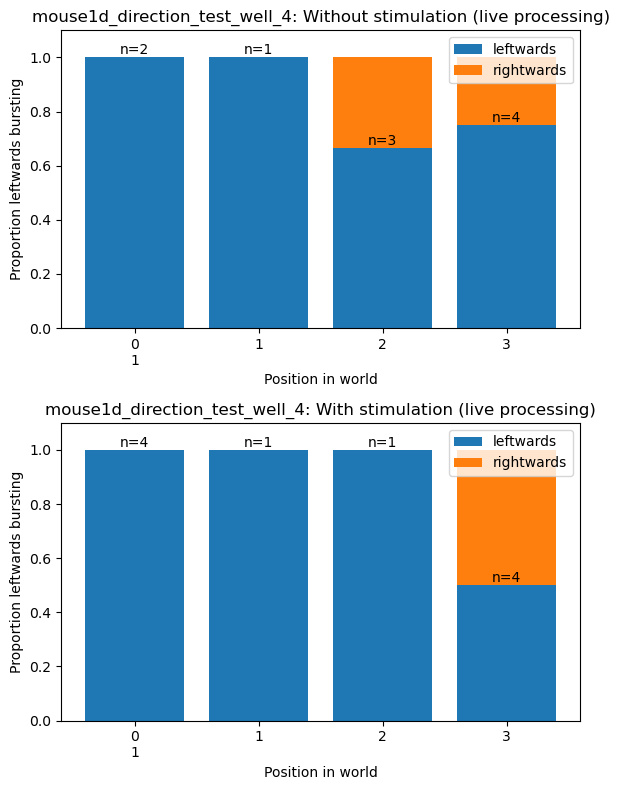

In [166]:
plt.figure(figsize = (6, 8))

ax = plt.subplot(212)
plt.title(filename + ": With stimulation (live processing)")
m1da.make_probability_bars(train_transition_df, world)

ax = plt.subplot(211)
plt.title(filename + ": Without stimulation (live processing)")
m1da.make_probability_bars(pre_train_transition_df, world)

plt.tight_layout()

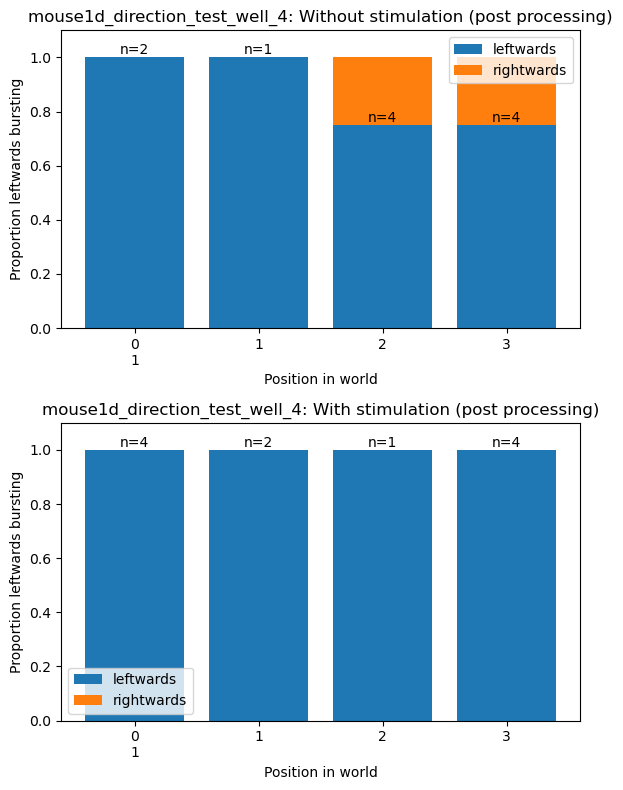

In [167]:
plt.figure(figsize = (6, 8))
plt.subplot(211)
plt.title(filename + ": Without stimulation (post processing)")
m1da.make_probability_bars(pre_train_raw_data_transition_df, world)

plt.subplot(212)
plt.title(filename + ": With stimulation (post processing)")
m1da.make_probability_bars(train_raw_data_transition_df, world)

plt.tight_layout()
